In [1]:
# Basic packages supporting CLIP and GEFI
import torch
import clip
from gefi import gefi
import torch.nn.functional as F
import numpy as np
import model_adapter
from processing import img_related
from PIL import Image

# Packages for animation generation
import matplotlib
from matplotlib.colors import TwoSlopeNorm
from matplotlib import pyplot as plt   
from interaction_visualization import visualize_text, visualize_image, score_scaling
from interaction_visualization import animation 

# Other utility functions
import utils
from utils import log
from pathlib import Path
from time import perf_counter
from contextlib import contextmanager


matplotlib.rcParams["text.latex.preamble"]=r"\usepackage{amsmath}"
plt.rcParams["font.family"] = "monospace"

@contextmanager
def timed_stage(timings, stage):
    """Accumulate wall time across repeated operations in a stage."""
    start = perf_counter()
    try:
        yield
    finally:
        timings[stage] = timings.get(stage, 0.0) + perf_counter() - start

def read_sample_raw(example_dir):
    """Read an exported example's RGB image and caption."""
    folder = Path(example_dir)
    with Image.open(folder / "raw_image.jpg") as source:
        image = source.convert("RGB")
    caption = (folder / "caption.txt").read_text(encoding="utf-8").strip()
    return image, caption

e:\env\llm\Lib\site-packages\clip\clip.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import packaging


In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
clipmodel, preprocess = model_adapter.load_clip("ViT-B/32", device)
tokenizer = model_adapter.OpenAIClipTokenizerAdapter()

clip_inres = clipmodel.visual.input_resolution
clip_ksize = clipmodel.visual.conv1.kernel_size
RANDOM_SEED = 0

print("[clip resolution]:", clip_inres)
print("[clip kernel size]:", clip_ksize)


[clip resolution]: 224
[clip kernel size]: (32, 32)


## Collecting observations

In [3]:
# Initialize explainer and model
IMG_SIZE = (3, 224, 224)
TXT_SIZE = 77

""" 
Check more details about image baseline in baseline_generation.py,
using the blurred version of the input generally produces good visual results
"""
img_baseline = "blur"   
txt_baseline = 0
num_samples = 5000

utils.set_seed(RANDOM_SEED)
expl = gefi.GEFI4Clip(
    num_samples, IMG_SIZE, TXT_SIZE, 
    img_baseline=img_baseline, txt_baseline=txt_baseline,
    truncation=0.25, img_ratio=0.8, patch_size=32
)

INFO[10/29/26,14:30:17]:	GEFI initializing query masks, might take some time


e:\workspace\xai\GEFI\gefi\mask_generator.py:145: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.size = torch.tensor(target_size)[-2:]


INFO[10/29/26,14:30:21]:	A plate of finger foods next to a blue and raspberry topped cake.
INFO[10/29/26,14:30:21]:	CLIP cosine similarity: 0.3396


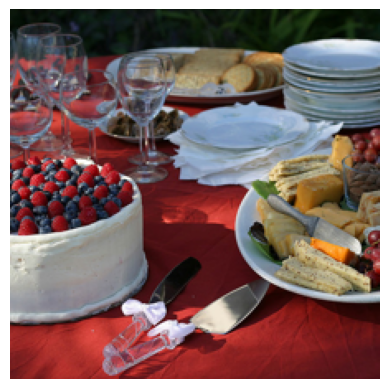

In [4]:
example_dir = "./examples/gif_example_000000002157/"
org_img, caption = read_sample_raw(example_dir)
img = preprocess(org_img).unsqueeze(0)
txt = clip.tokenize([caption])

plt.imshow(img_related.unnormalize2show(img)), plt.axis("off")

with torch.no_grad():
    image_embedding = F.normalize(clipmodel.encode_image(img.to(device)), dim=-1)
    text_embedding = F.normalize(clipmodel.encode_text(txt.to(device)), dim=-1)
    similarity = (image_embedding @ text_embedding.T).item()
log(caption)
log(f"CLIP cosine similarity: {similarity:.4f}")

In [5]:
# Collecting observations for latter reuse
with torch.no_grad():
    obs = expl.collect_observations(clipmodel, img, txt, cv_mode=3)

# Visualizing interactions through animation

In [6]:
SAVE_GIF = True
batch_size = 4
# Text plotting configuration
fontsize = 10
text_band_height = 40
gap_word, gap_subword = 6, 2
# Visual quality
figure_dpi = 96

edgecolor_str = "#32CD32"
edgecolor = visualize_image.color_hex2rgb(edgecolor_str)
pos_color_str, neg_color_str = "#cd5c5c", "#4169E1", 
facecolor_pos, facecolor_neg = visualize_image.color_hex2rgb(pos_color_str), visualize_image.color_hex2rgb(neg_color_str)


### Interaction anchored on texts

In [7]:
txt2img_timings = {"Frame drawing": 0.0,}
if obs.is_cuda:
    torch.cuda.synchronize(obs.device)
txt2img_started = perf_counter()

with timed_stage(txt2img_timings, "Interaction computation"):
    # Explaining
    valid_contents = gefi.get_contents(txt[0])
    tokens, has_spaces = visualize_text.decode_clip_tokens(tokenizer, valid_contents)
    token_idxs = list(range(1, len(tokens)+1))
    img_estimates = []
    for ptr in range(0, len(token_idxs), batch_size):
        img_estimates.append(expl.interaction_anchored_on_text(obs, token_idxs[ptr:ptr+batch_size]))
    img_estimates = torch.vstack(img_estimates)

    if obs.is_cuda:
        torch.cuda.synchronize(obs.device)
log(f"Interaction computation: {txt2img_timings['Interaction computation']:.3f}s")

with timed_stage(txt2img_timings, "Canvas and text setup"):
    # Set up same scale for cross-anchor interaction comprehension  
    vmax = img_estimates.abs().max().clamp_min(torch.finfo(img_estimates.dtype).tiny).item()
    norm = TwoSlopeNorm(0, -vmax, vmax)

    ''' ========== Visualization ========== '''
    # Initiating canvas
    fig, ax = plt.subplots(figsize=(6, 6), dpi=figure_dpi)
    # Enhancement is invariant across transition frames; compute once per token.
    enhanced_maps = np.stack([
        expl.visual_enhancement(img, estimate).numpy() for estimate in img_estimates
    ])
    enhanced = enhanced_maps[0]
    img_artist = ax.imshow(enhanced, cmap="coolwarm", norm=norm)
    h, w = enhanced.shape[-2:]
    full_boxinfo = visualize_text.draw_text_only(
        ax, tokens, has_spaces, 
        img_width=w, img_height=h, band_height=text_band_height,
        fontsize=fontsize, gap_word=gap_word, gap_subword=gap_subword,
    )[1]
    boxinfo = [info for info, artist in full_boxinfo]
    renderer = animation.TextAnchorRenderer(
        ax, enhanced.shape, norm, matplotlib.colormaps["coolwarm"], 
        edgecolor, linewidth=1.5
    )
    plt.close(fig)  # All remaining frames are composed directly with Pillow.

    max_exposure, min_exposure = 300, 50
    main_frame_additional = 500
    transition_frames = 15
    frames, exposures = [], []


# Draw by frame
frame_loop_started = perf_counter()
for i in range(len(img_estimates)):
    current_enhanced = enhanced_maps[i]

    if i+1 < len(img_estimates):
        boxes, factors = animation.bbox_transition(boxinfo[i]["bbox_xywh"], boxinfo[i+1]["bbox_xywh"], frames=transition_frames)
        boxes = boxes[:-1]
        factors = factors[:-1]
        intensity = np.abs(factors*2 - 1)
        new_exposures = (intensity * max_exposure + (1-intensity) * min_exposure).tolist()
        new_exposures[0] += main_frame_additional
        exposures += new_exposures
        next_enhanced = enhanced_maps[i+1]
    else:
        boxes, factors = np.array([boxinfo[i]["bbox_xywh"]]), np.array([0.])
        exposures.append(max_exposure + main_frame_additional)
        intensity = [1.]
        next_enhanced = np.zeros_like(current_enhanced)

    with timed_stage(txt2img_timings, "Frame drawing"):
        for box, t, visibility in zip(boxes, factors, intensity): 
            content = current_enhanced if t < 0.5 else next_enhanced
            content = content * abs(t*2-1)  # scaling visibility, less visible content during transition
            frame = renderer.render(content, box, visibility**2)
            frames.append(frame)

# Remaining loop time covers transition preparation and scalar-map fading.
txt2img_timings["Transition preparation"] = (
    perf_counter() - frame_loop_started
    - txt2img_timings["Frame drawing"]
)
log(f"Rendered {len(frames)} frames; saving txt2img.gif ...")

exposures[0] += main_frame_additional // 2
exposures[-1] += main_frame_additional // 2

if SAVE_GIF:    # opt-in SAVE_GIF to create a copy in current folder
    with timed_stage(txt2img_timings, "GIF saving"):
        # Slower saving without visual distortion
        frames[0].save("txt2img.gif", save_all=True, append_images=frames[1:], duration=exposures, loop=0, optimize=False)
else:           # opt-out SAVE_GIF to show high quality animation in notebook cell
    with timed_stage(txt2img_timings, "GIF Display"):
        animation.display_frames(frames, exposures, loop=True)  # text-to-image

txt2img_total = perf_counter() - txt2img_started
log(f"Text-to-image timing: {len(tokens)} tokens, {len(frames)} frames")
for stage, seconds in txt2img_timings.items():
    log(f"  {stage:30s} {seconds:8.3f}s  ({seconds / txt2img_total:6.1%})")
log(f"  {'Total wall time':30s} {txt2img_total:8.3f}s")
log(f"  Drawing: {1000 * txt2img_timings['Frame drawing'] / len(frames):.2f} ms/frame")


INFO[10/29/26,14:30:24]:	Interaction computation: 0.414s
INFO[10/29/26,14:30:25]:	Rendered 183 frames; saving txt2img.gif ...
INFO[10/29/26,14:30:26]:	Text-to-image timing: 14 tokens, 183 frames
INFO[10/29/26,14:30:26]:	  Frame drawing                     0.279s  ( 12.9%)
INFO[10/29/26,14:30:26]:	  Interaction computation           0.414s  ( 19.1%)
INFO[10/29/26,14:30:26]:	  Canvas and text setup             0.130s  (  6.0%)
INFO[10/29/26,14:30:26]:	  Transition preparation            0.002s  (  0.1%)
INFO[10/29/26,14:30:26]:	  GIF saving                        1.335s  ( 61.8%)
INFO[10/29/26,14:30:26]:	  Total wall time                   2.161s
INFO[10/29/26,14:30:26]:	  Drawing: 1.53 ms/frame


### Interaction anchored on image 

INFO[10/29/26,14:30:26]:	Visualize the trajectory


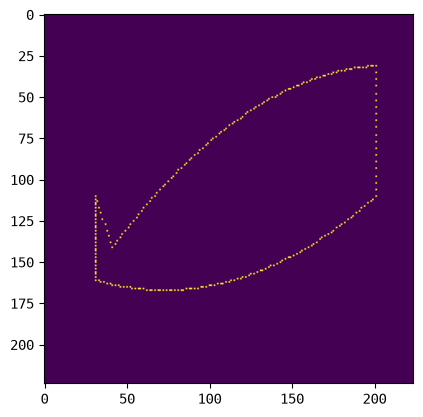

In [8]:
# Create trajectory
circle_mask = torch.zeros(IMG_SIZE[-2:])
key_points = [
    (31, 201), 
    (110, 201),
    (161, 31), 
    (110, 31),
    (141, 41)
]

# Configuring the path
start, right_mid = key_points[:2]
left_down, left_up = key_points[2:4]
left_mid = key_points[-1]

pos_line = visualize_image.line_trajectory(start, right_mid, n_points=20)
pos_curve = visualize_image.curved_trajectory(right_mid, left_down, n_points=100, bend=50)
pos_line_up = visualize_image.line_trajectory(left_down, left_up, n_points=30)
pos_line_right_down = visualize_image.line_trajectory(left_up, left_mid, n_points=10)
pos_forward = np.vstack([pos_line, pos_curve, pos_line_up, pos_line_right_down])

pos_back = visualize_image.curved_trajectory(left_mid, start, n_points=100, bend=-50)
ys, xs = pos_forward[:, 0], pos_forward[:, 1]
circle_mask[ys, xs] = 1
ys, xs = pos_back[:, 0], pos_back[:, 1]
circle_mask[ys, xs] = 1
plt.imshow(circle_mask)
log("Visualize the trajectory")

In [9]:
# Build one ordered mask sequence and its matching frame durations.
radius = 20
max_radius = 39
reusable_mask = visualize_image.RoundMask(2 * radius + 1, radius)
anchor_masks, durations = [], []

for position in pos_forward:
    anchor_masks.append(reusable_mask.generate_mask(*position).bool())
    durations.append(100)

for current_radius in range(radius, max_radius + 1):
    expanding_mask = visualize_image.RoundMask(2 * current_radius + 1, current_radius)
    anchor_masks.append(expanding_mask.generate_mask(*left_mid).bool())
    durations.append(150)

for i, position in enumerate(pos_back):
    current_radius = max(max_radius - i * 2, radius)
    returning_mask = visualize_image.RoundMask(2 * current_radius + 1, current_radius)
    anchor_masks.append(returning_mask.generate_mask(*position).bool())
    durations.append(100)


In [ ]:
# Additional text highlighting configuration
kernel_width = 7
background_alpha = 0.4
t_per_frame, t_per_feature = 1.0, 0.3

img2txt_timings = dict()
if obs.is_cuda:
    torch.cuda.synchronize(obs.device)
img2txt_started = perf_counter()

with timed_stage(img2txt_timings, "Interaction computation"):
    valid_contents = gefi.get_contents(txt[0])
    tokens, has_spaces = visualize_text.decode_clip_tokens(tokenizer, valid_contents)
    log("Deriving interactions by image anchors")
    scores = expl.interaction_anchored_on_image(obs, torch.stack(anchor_masks))
    if obs.is_cuda:
        torch.cuda.synchronize(obs.device)
log(f"Interaction computation: {img2txt_timings['Interaction computation']:.3f}s")

with timed_stage(img2txt_timings, "Canvas, caption and image setup"):
    frame_magnitudes = scores.abs().sum(dim=1)
    frame_factors = score_scaling.scores_to_alpha(frame_magnitudes, temperature=t_per_frame)
    # Normalize the base image once; no tensor image operations in the frame loop.
    image_rgb = img_related.unnormalize2show(img).numpy()
    image_rgb = np.rint(np.clip(image_rgb, 0, 1) * 255).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(6, 6), dpi=figure_dpi)
    ax.imshow(image_rgb)
    h, w = image_rgb.shape[:2]
    full_boxinfo = visualize_text.draw_text_only(
        ax, tokens, has_spaces,
        img_width=w, img_height=h, band_height=text_band_height,
        fontsize=fontsize, gap_word=gap_word, gap_subword=gap_subword,
    )[1]
    boxinfo = [info for info, artist in full_boxinfo]
    image_renderer = animation.ImageAnchorRenderer(
        ax, image_rgb, boxinfo, edgecolor, facecolor_pos, facecolor_neg,
        boundary_width=kernel_width, background_alpha=background_alpha,
    )
    plt.close(fig)
    # Opacities and CPU arrays are also invariant during composition.
    token_alphas = [
        np.asarray(score_scaling.scores_to_alpha(row, temperature=t_per_feature)) * factor
        for row, factor in zip(scores, frame_factors)
    ]
    score_arrays = scores.numpy()
    mask_arrays = [mask.numpy() for mask in anchor_masks]

frames = []
log("Composing frames with Pillow")
with timed_stage(img2txt_timings, "Frame drawing"):
    for mask, token_scores, alphas in zip(mask_arrays, score_arrays, token_alphas):
        frame = image_renderer.render(mask, token_scores, alphas)
        frames.append(frame)

if SAVE_GIF:
    log("Saving frames as GIF, might take some time ...")
    with timed_stage(img2txt_timings, "GIF saving"):
        # Split palette: 192 image colors, 64 caption colors; dither only the image.
        img2txt_encoding_timings = animation.save_gif_shared_palette(
            frames, "img2txt.gif", durations,
            key_colors=(edgecolor, facecolor_pos, facecolor_neg),
            caption_top=image_renderer.caption_top, image_colors=192,
            dither_image=True,
        )
else:
    with timed_stage(img2txt_timings, "GIF Display"):
        animation.display_frames(frames, durations, loop=1)  # image-to-text

img2txt_total = perf_counter() - img2txt_started
print(f"Image-to-text timing: {len(tokens)} tokens, {len(frames)} frames")
for stage, seconds in img2txt_timings.items():
    print(f"  {stage:43s} {seconds:8.3f}s  ({seconds / img2txt_total:6.1%})")
print(f"  {'Total wall time':43s} {img2txt_total:8.3f}s")
print(f"  Drawing: {1000 * img2txt_timings['Frame drawing'] / len(frames):.2f} ms/frame")
